# Week 8-J: Frozen DEV benchmark

This notebook runs actual SARA generation on 231 DEV queries from 86 papers, with the FIT-frozen B0-GW gate, S3 selector and U4-A safety model. It shares original-SARA drafts/actions across G0/G1 and all three fixed W8-G revision adapters. STOP returns the original draft; harmful revisions remain in the results. No training, tuning or winner selection occurs.

**DEV has been inspected in earlier weeks. This is development evaluation, not a pristine final test. TEST stays unused.** Historical static semantic k2/k4/k5/k6/k8 answers are rescored with the current scorer; their actual serialized prompt tokens are rebuilt. New original k4 generations must match the canonical DEV answers before routing proceeds. No zero embeddings or proxy predictions are allowed.

Run the real 20-query GPU smoke first. Set `RUN_FULL=True` in the first cell to continue to all 231 queries. Runs resume under source fingerprints; smoke/full outputs are separate. Keep a GPU-enabled `sara_env` kernel with at least 18 GiB free GPU memory. Cumulative prompt tokens are a compute proxy; timings exclude cached retrieval/SFR and cold model loading. DAFiR-2 and QCLA/controller stacking are not evaluated.

In [1]:
import sys, subprocess, json
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'configs/week8/w8_dafir.yaml').is_file())
SCRIPT = ROOT / 'scripts/week8/run_w8j_final_dev_benchmarks.py'
OUTPUT = ROOT / 'results/week8/w8j_final_dev'
RUN_FULL = True
def run(mode):
    subprocess.run([sys.executable, str(SCRIPT), mode, '--output-dir', str(OUTPUT)], cwd=ROOT, check=True)
run('--check')


Inputs verified: 231 queries; live B0-GW + S3/U4-A; paired G0/G1; variants ['original_SARA', 'uniform_SFT', 'HC_LoRA', 'OW_LoRA'] | CUDA available: True | real GPU smoke required before full execution


Run the smoke check. A successful cell produces measured results and enables full execution.

In [2]:
run('--smoke')
SMOKE_PASSED = True
display(pd.read_csv(OUTPUT / 'smoke/benchmark.csv'))

Verified completed measured W8-J run: /home/gunavenkat/Downloads/CS787-RAG-Project/results/week8/w8j_final_dev/smoke


,system,queries,mean_token_f1,mean_final_prompt_tokens,mean_cumulative_prompt_tokens,promotion_rate
0,original_SARA/G0,20,0.429845,1006.45,1317.30,0.3
1,original_SARA/G1,20,0.436512,1024.35,1335.20,0.3
2,uniform_SFT/G0,20,0.429845,1006.45,1317.30,0.3
3,uniform_SFT/G1,20,0.436512,1024.35,1335.20,0.3
4,HC_LoRA/G0,20,0.429845,1006.45,1317.30,0.3
5,HC_LoRA/G1,20,0.429845,1024.35,1335.20,0.3
6,OW_LoRA/G0,20,0.429845,1006.45,1317.30,0.3
7,OW_LoRA/G1,20,0.436512,1024.35,1335.20,0.3
8,semantic_k2,20,0.278661,517.70,517.70,NaN
9,semantic_k4,20,0.429845,940.40,940.40,NaN


Full evaluation and paired paper-clustered intervals (2,000 resamples). Intervals are exploratory and are not corrected for multiple comparisons.

`torch_dtype` is deprecated! Use `dtype` instead!
Loading checkpoint shards: 100%|██████████| 3/3 [00:00<00:00, 116.38it/s]
Some weights of XMistralForCausalLM were not initialized from the model checkpoint at mistralai/Mistral-7B-Instruct-v0.2 and are newly initialized: ['projector.projector.0.bias', 'projector.projector.0.weight', 'projector.projector.2.bias', 'projector.projector.2.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`
The new lm_head weights will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `

      variant revision_mode  queries  downstream_f1  base_k4_f1  gain_over_k4  exact_match  promotion_rate  hurt_rate_all_queries  help_precision_promotions  hurt_rate_promotions  mean_final_prompt_tokens  mean_cumulative_prompt_tokens  mean_generated_tokens  mean_timed_query_compute_seconds reference_action_agreement end_to_end_latency_sec
original_SARA            G0      231       0.410104    0.390929      0.019174     0.229437        0.363636               0.025974                   0.154762              0.071429                997.727273                    1336.393939              24.311688                          4.548117                       None                   None
original_SARA            G1      231       0.397550    0.390929      0.006621     0.220779        0.363636               0.004329                   0.047619              0.011905               1022.839827                    1361.506494              23.562771                          4.580694                      

,system,queries,mean_token_f1,mean_final_prompt_tokens,mean_cumulative_prompt_tokens,promotion_rate
0,original_SARA/G0,231,0.410104,997.727273,1336.393939,0.363636
1,original_SARA/G1,231,0.397550,1022.839827,1361.506494,0.363636
2,uniform_SFT/G0,231,0.395601,997.727273,1336.393939,0.363636
3,uniform_SFT/G1,231,0.402915,1022.839827,1361.506494,0.363636
4,HC_LoRA/G0,231,0.405947,997.727273,1336.393939,0.363636
5,HC_LoRA/G1,231,0.396658,1022.839827,1361.506494,0.363636
6,OW_LoRA/G0,231,0.405752,997.727273,1336.393939,0.363636
7,OW_LoRA/G1,231,0.404290,1022.839827,1361.506494,0.363636
8,semantic_k2,231,0.311819,517.619048,517.619048,NaN
9,semantic_k4,231,0.390929,929.056277,929.056277,NaN


,treatment,control,delta_f1,ci95_low,ci95_high,queries,papers,resamples,interval_method
0,original_SARA/G0,semantic_k4,0.019174,0.000643,0.038968,231,86,2000,paired paper-cluster percentile bootstrap; que...
1,original_SARA/G1,semantic_k4,0.006621,-0.008153,0.022425,231,86,2000,paired paper-cluster percentile bootstrap; que...
2,uniform_SFT/G0,semantic_k4,0.004672,-0.021680,0.031917,231,86,2000,paired paper-cluster percentile bootstrap; que...
3,uniform_SFT/G1,semantic_k4,0.011985,-0.000788,0.028762,231,86,2000,paired paper-cluster percentile bootstrap; que...
4,HC_LoRA/G0,semantic_k4,0.015018,-0.005277,0.037614,231,86,2000,paired paper-cluster percentile bootstrap; que...
5,HC_LoRA/G1,semantic_k4,0.005729,-0.000797,0.015884,231,86,2000,paired paper-cluster percentile bootstrap; que...
6,OW_LoRA/G0,semantic_k4,0.014823,-0.007157,0.038830,231,86,2000,paired paper-cluster percentile bootstrap; que...
7,OW_LoRA/G1,semantic_k4,0.013361,0.001248,0.029523,231,86,2000,paired paper-cluster percentile bootstrap; que...
8,semantic_k2,semantic_k4,-0.079110,-0.118586,-0.043115,231,86,2000,paired paper-cluster percentile bootstrap; que...
9,semantic_k4,semantic_k4,0.000000,0.000000,0.000000,231,86,2000,paired paper-cluster percentile bootstrap; que...


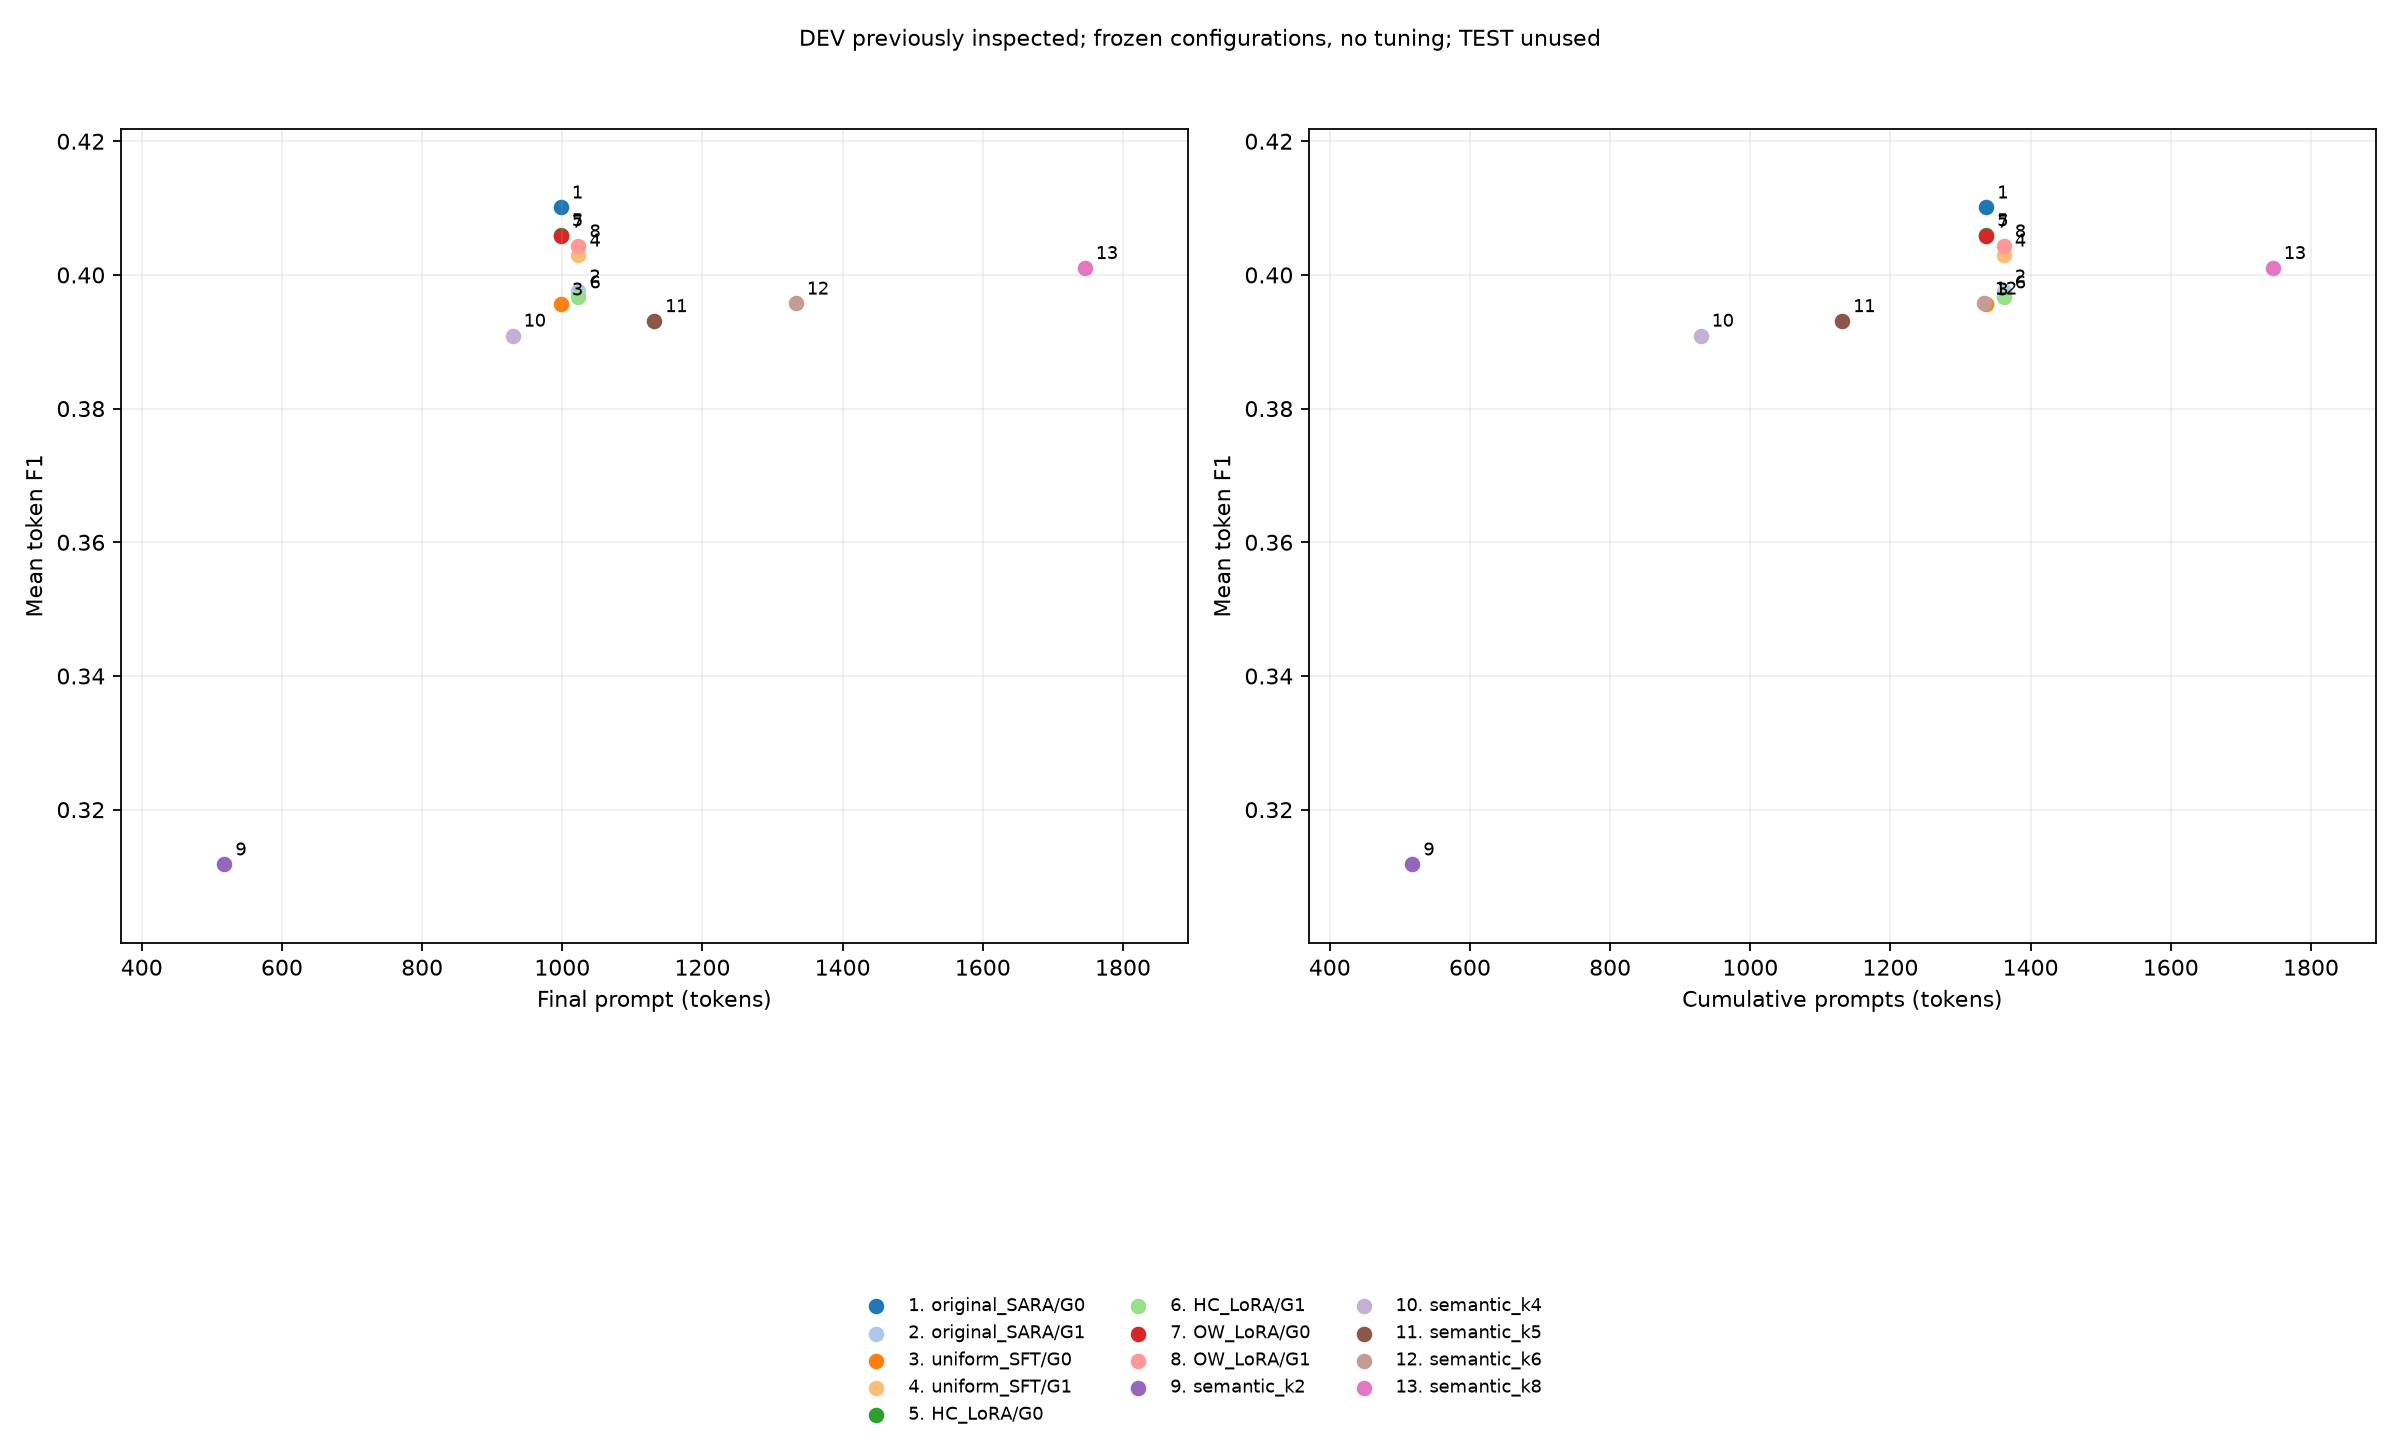

In [3]:
if RUN_FULL:
    if not globals().get('SMOKE_PASSED', False):
        raise RuntimeError('Run the smoke cell successfully first.')
    run('--full')
    display(pd.read_csv(OUTPUT / 'full/benchmark.csv'))
    display(pd.read_csv(OUTPUT / 'full/paired_paper_intervals.csv'))
    display(Image(filename=str(OUTPUT / 'full/quality_cost.png')))
else:
    print('Smoke complete. Set RUN_FULL=True in the first cell, then rerun it and this cell for the full evaluation.')
